<a href="https://colab.research.google.com/github/ggvtw/MPS311/blob/main/240153092.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.model_selection import KFold, cross_val_score, cross_val_predict
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.compose import TransformedTargetRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.base import BaseEstimator, RegressorMixin, clone

In [37]:
test = pd.read_csv("https://raw.githubusercontent.com/ggvtw/MPS311/main/test.csv")
train = pd.read_csv("https://raw.githubusercontent.com/ggvtw/MPS311/main/train.csv")
kf = KFold(n_splits=5, shuffle=True, random_state=0)

In [38]:
y = train["median_house_value"]
X = train.drop(columns=["median_house_value", "ocean_proximity"])

for name, model in [("mean initial CV RMSE", DummyRegressor(strategy="mean")),
                    ("linear regression CV RMSE", LinearRegression())]:
                    s = cross_val_score(model, X, y, cv=kf, scoring="neg_root_mean_squared_error")
                    print(name, -s.mean())

mean initial CV RMSE 0.9465035429580622
linear regression CV RMSE 0.5799262132029946


### Starting Baseline
- **Simple baseline (just predicting the mean)**: Gives an RMSE of **0.9465**.
- **Standard Linear Regression**: Decreases to **0.5799**.

Dropping the error that much straight away shows us that coordinates and basic house details  have a lot of predictive power.

In [39]:
predictLR = cross_val_predict(LinearRegression(), X, y, cv=kf)
residualsLR = y - predictLR

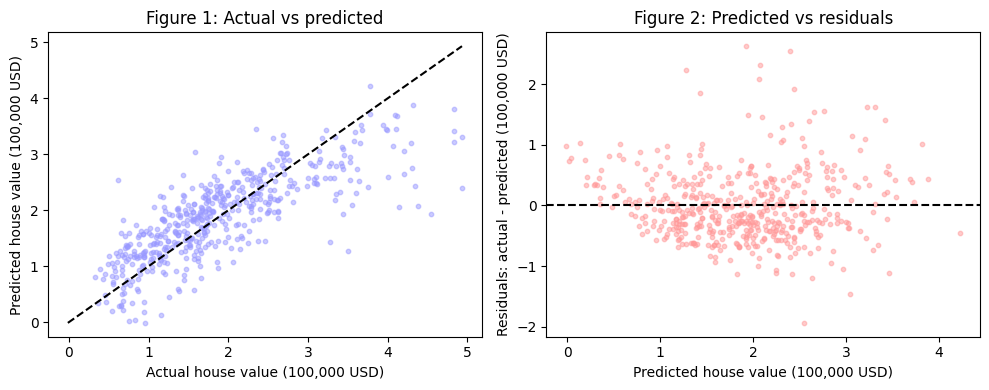

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].scatter(y, predictLR, alpha=0.5, s=10, c = "#9999ff")
lims = [min(y.min(), predictLR.min()), max(y.max(), predictLR.max())]
ax[0].plot(lims, lims, "k--")
ax[0].set_xlabel("Actual house value (100,000 USD)")
ax[0].set_ylabel("Predicted house value (100,000 USD)")
ax[0].set_title("Figure 1: Actual vs predicted")

ax[1].scatter(predictLR, residualsLR, alpha=0.5, s=10, c = "#ff9999")
ax[1].axhline(0, color="k", linestyle="--")
ax[1].set_xlabel("Predicted house value (100,000 USD)")
ax[1].set_ylabel("Residuals: actual - predicted (100,000 USD)")
ax[1].set_title("Figure 2: Predicted vs residuals")

plt.tight_layout()
plt.savefig("fig1_2.png", dpi=200)
plt.show()


### Ratio Features
I have added the following averages to the data set
1. **Rooms per Household**: Tells us how big the average house is in that block.
2. **Bedrooms per Room**: Tells us the proportion of rooms in the house that are bedrooms
3. **Population per Household**: Tells us how many people live in each home.

In [41]:
cols = ["longitude", "latitude", "housing_median_age", "total_rooms", "total_bedrooms", "population", "households", "median_income"]
x_base = train[cols]
x_new = x_base.copy()
x_new["rooms_per_household"] = x_new["total_rooms"] / x_new["households"]
x_new["bedrooms_per_room"] = x_new["total_bedrooms"] / x_new["total_rooms"]
x_new["population_per_household"] = x_new["population"] / x_new["households"]


In [42]:
def cv_scores(X) :
  return -cross_val_score(LinearRegression(), X, y, cv=kf, scoring="neg_root_mean_squared_error")
base = cv_scores(x_base)
new = cv_scores(x_new)
print("Base LR RMSE:" , base.mean())
print("New RMSE:" , new.mean())
print("Change:" , new.mean() - base.mean())
print("Improvement per fold:" , new - base)
print("Improvement over baseline:" , (new < base).sum(), "of 5")

Base LR RMSE: 0.5799262132029946
New RMSE: 0.5618981609323274
Change: -0.018028052270667283
Improvement per fold: [-0.02879155  0.01567291 -0.00242375 -0.03645189 -0.03814598]
Improvement over baseline: 4 of 5


### Ratios effect
- **Before**: 0.5799
- **With ratios**: 0.5619
- **Improvement**: -0.0180

The ratio features helped in 4 out of the 5 cross-validation folds.

### Looking at the errors (Figures 1 & 2)
1. **High underpredictions**: There's a cluster of points where the model predicted a much lower value than reality (positive residuals up to ~2.6). This means I am missing something that makes certain blocks highly valuable.
2. **Curvature**: The residuals in Figure 2 show a slight U-shape, meaning the relationships might not be perfectly straight lines.
3. **Below-zero predictions**: A few predictions are practically zero, which doesn't make sense for real estate.

Let's try log-transforming income next to see if that helps with the non-linearity.

In [43]:
print((y == y.max()).sum(), y.max())
print(residualsLR[y == y.max()].describe())

1 4.934
count    1.000000
mean     1.623317
std           NaN
min      1.623317
25%      1.623317
50%      1.623317
75%      1.623317
max      1.623317
Name: median_house_value, dtype: float64


### Checking the 500k cap
I wanted to see if the tail of high residuals was because house prices are capped at $500k in this dataset. There is only one block at the maximum price limit in our training set (underpredicted by 1.62). So, the cap isn't what's causing our large errors.

In [44]:
big = residualsLR > 1
print(f"Number of large positive residuals (> 1): {big.sum()}")
print("\nMean values for high-error blocks:")
print(x_base[big].mean())
print("\nMean values for all training blocks:")
print(x_base.mean())

Number of large positive residuals (> 1): 27

Mean values for high-error blocks:
longitude             -119.001111
latitude                34.725185
housing_median_age      31.000000
total_rooms           2284.888889
total_bedrooms         503.962963
population            1139.370370
households             474.370370
median_income            4.036619
dtype: float64

Mean values for all training blocks:
longitude             -119.555660
latitude                35.617460
housing_median_age      26.450000
total_rooms           2714.626000
total_bedrooms         559.450000
population            1498.284000
households             519.244000
median_income            3.609441
dtype: float64


### High Error Blocks
When we look at blocks where our predictions are off by more than 1.0 (underpredicting), they tend to have slightly older houses, higher average incomes, and smaller neighborhoods. But these differences are quite small, so geography is likely the cause.

In [45]:
print(train.loc[big, "ocean_proximity"].value_counts())
print(train["ocean_proximity"].value_counts())

ocean_proximity
<1H OCEAN     19
INLAND         4
NEAR BAY       2
NEAR OCEAN     2
Name: count, dtype: int64
ocean_proximity
<1H OCEAN     238
INLAND        160
NEAR OCEAN     61
NEAR BAY       41
Name: count, dtype: int64


In [46]:
x_ocean = pd.get_dummies(train[cols + ["ocean_proximity"]],
                         columns=["ocean_proximity"], dtype=float)
oc = cv_scores(x_ocean)
print(base.mean(), oc.mean(), oc.mean() - base.mean())
print(oc - base)

0.5799262132029946 0.5752621505564162 -0.004664062646578482
[-0.01251603 -0.017813    0.00308998 -0.00169722  0.00561596]


### Ocean Proximity effect
Adding the categorical ocean proximity variables barely helps (an improvement of only **-0.0047** RMSE), and it only helped in 3 of the 5 folds. We will leave this out to keep the model simple.

In [47]:
x_log = x_base.copy()
x_log["log_income"] = np.log(x_log["median_income"])

base = cv_scores(x_base)
log = cv_scores(x_log)

print("baseline:", base.mean())
print("log income:", log.mean())
print("change:", log.mean() - base.mean())
print("improvement per fold:", log - base)
print("folds improved:", (log<base).sum(), "of 5")

baseline: 0.5799262132029946
log income: 0.5785755299282613
change: -0.0013506832747333108
improvement per fold: [-0.00568495 -0.00015464  0.00079368 -0.00620171  0.0044942 ]
folds improved: 3 of 5


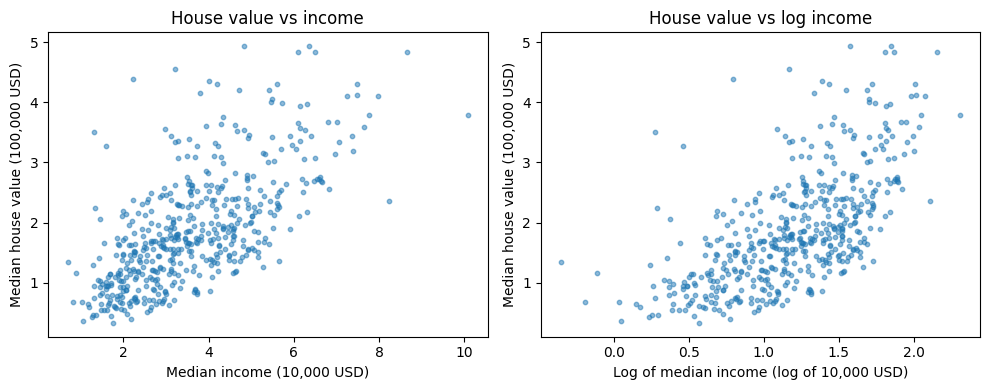

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(x_base["median_income"], y, alpha=0.5, s=10)
ax[0].set_xlabel("Median income (10,000 USD)")
ax[0].set_ylabel("Median house value (100,000 USD)")
ax[0].set_title("House value vs income")
ax[1].scatter(np.log(x_base["median_income"]), y, alpha=0.5, s=10)
ax[1].set_xlabel("Log of median income (log of 10,000 USD)")
ax[1].set_ylabel("Median house value (100,000 USD)")
ax[1].set_title("House value vs log income")
plt.tight_layout()
plt.show()


### Trying Log-Income
- **Baseline**: 0.5799
- **Log-Income**: 0.5786
- **Change**: -0.0014

Using the logarithm of median income didn't change anything. The raw relationship is already mostly linear, so we don't need to overcomplicate it with a log transform.

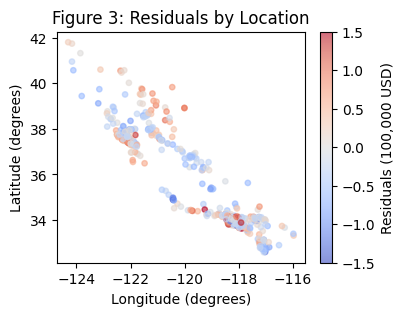

In [49]:
plt.figure(figsize=(4,3))
sc = plt.scatter(train["longitude"], train["latitude"], c = residualsLR, cmap = "coolwarm", vmin = -1.5, vmax = 1.5, s = 15, alpha = 0.6)
plt.colorbar(sc, label = "Residuals (100,000 USD)")
plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")
plt.title("Figure 3: Residuals by Location")
plt.show()

### Mapping the errors
When I plot where the model is making the biggest mistakes (Figure 3), I can clearly see clusters of bright red (underpredictions) right around San Francisco and Los Angeles. I am going to add features for how close a block is to these major cities.

In [50]:
def dist(lon0, lat0, df=x_base):
    return np.sqrt((df["longitude"] - lon0)**2 + (df["latitude"] - lat0)**2)

x_city = x_base.copy()
x_city["dist_sf"] = dist(-122.4, 37.8)
x_city["dist_la"] = dist(-118.2, 34.05)

In [51]:
city = cv_scores(x_city)
print("baseline:", base.mean())       # should still be 0.5799
print("with distances:", city.mean())
print("change:", city.mean() - base.mean())
print("per fold:", city - base)
print("folds improved:", (city < base).sum(), "of 5")



baseline: 0.5799262132029946
with distances: 0.5712358595177545
change: -0.008690353685240182
per fold: [-0.00849374 -0.01549465  0.01299394 -0.01360525 -0.01885207]
folds improved: 4 of 5


### Adding distances to SF & LA
- **Baseline**: 0.5799
- **With City Distances**: 0.5712
- **Change**: -0.0087

Adding the distance to SF and LA improved 4 out of the 5 folds. Proximity to these cities definitely explains some of the  variation.

In [52]:
x_both = x_new.copy()          # baseline + 3 ratio features
x_both["dist_sf"] = x_city["dist_sf"]
x_both["dist_la"] = x_city["dist_la"]

both = cv_scores(x_both)
print("ratios only:", cv_scores(x_new).mean())
print("ratios + distances:", both.mean())
print("change vs baseline:", both.mean() - base.mean())
print("folds improved vs baseline:", (both < base).sum(), "of 5")
print("folds improved vs ratios only:", (both < cv_scores(x_new)).sum(), "of 5")


ratios only: 0.5618981609323274
ratios + distances: 0.5521925958566217
change vs baseline: -0.02773361734637292
folds improved vs baseline: 4 of 5
folds improved vs ratios only: 4 of 5


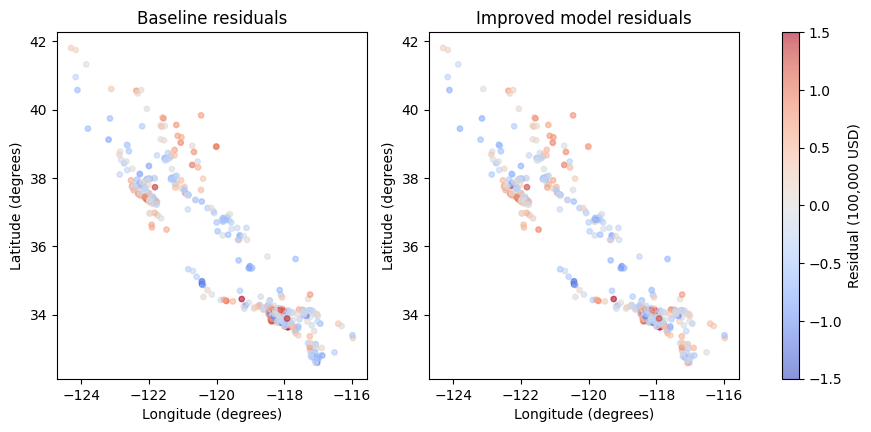

In [53]:
pred_both = cross_val_predict(LinearRegression(), x_both, y, cv=kf)
resid_both = y - pred_both

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, r, t in [(ax[0], residualsLR, "Baseline residuals"),
                (ax[1], resid_both, "Improved model residuals")]:
    sc = a.scatter(train["longitude"], train["latitude"], c=r,
                   cmap="coolwarm", vmin=-1.5, vmax=1.5, s=15, alpha=0.6)
    a.set_xlabel("Longitude (degrees)")
    a.set_ylabel("Latitude (degrees)")
    a.set_title(t)
fig.colorbar(sc, ax=ax, label="Residual (100,000 USD)")
plt.show()


In [54]:
rng = np.random.default_rng(0)
ratio_only = cv_scores(x_new)
changes = []
for _ in range(30):
    lon0 = rng.uniform(-124, -117)
    lat0 = rng.uniform(33, 41)
    lon1 = rng.uniform(-124, -117)
    lat1 = rng.uniform(33, 41)
    xr = x_new.copy()
    xr["d1"] = dist(lon0, lat0)
    xr["d2"] = dist(lon1, lat1)
    changes.append(cv_scores(xr).mean() - ratio_only.mean())

print("random hubs, mean change:", np.mean(changes))
print("best random change:", np.min(changes))
print("SF/LA change:", cv_scores(x_both).mean() - ratio_only.mean())


random hubs, mean change: -0.0022781009798405064
best random change: -0.016268096599149517
SF/LA change: -0.009705565075705636


### Random hub test
To make sure this improvement wasn't just a fluke from adding any random coordinates, I tested 30 pairs of completely random spots on the map.

- **Random spots average change**: -0.0023
- **SF/LA specific change**: -0.0097

SF and LA did better than the random points on average, showing that being close to those specific cities actually matters. Interestingly, the best random run did give a -0.0163, which tells us we might get even better results if we test other California cities.

In [55]:
x_city2 = x_base.copy()
x_city2["dist_sf"] = dist(-122.4, 37.8)
x_city2["dist_la"] = dist(-118.2, 34.05)
x_city2["dist_sj"] = dist(-121.9, 37.3)
x_city2["dist_sd"] = dist(-117.2, 32.7)
x_city2["dist_sc"] = dist(-121.5, 38.6)

In [56]:
x_city3 = x_base.copy()
x_city3["dist_sf"] = dist(-122.4, 37.8)
x_city3["dist_la"] = dist(-118.2, 34.05)
x_city3["dist_sj"] = dist(-121.9, 37.3)

In [57]:
x_5cities = x_new.copy()
city_cols = ["dist_sf", "dist_la", "dist_sj", "dist_sd", "dist_sc"]
x_5cities[city_cols] = x_city2[city_cols]

five_cities_scores = cv_scores(x_5cities)
ratios_scores = cv_scores(x_new)
print("5 cities:", five_cities_scores.mean())
print("ratios only:", ratios_scores.mean())
print("change:", five_cities_scores.mean() - ratios_scores.mean())
print("change vs baseline:", five_cities_scores.mean() - base.mean())
print("folds improved vs baseline:", (five_cities_scores < base).sum(), "of 5")
print("folds improved vs ratios only:", (five_cities_scores < cv_scores(x_new)).sum(), "of 5")

5 cities: 0.5556590089746106
ratios only: 0.5618981609323274
change: -0.006239151957716738
change vs baseline: -0.02426720422838402
folds improved vs baseline: 4 of 5
folds improved vs ratios only: 4 of 5


In [58]:
x_3cities = x_new.copy()
city_cols = ["dist_sf", "dist_la", "dist_sj"]
x_3cities[city_cols] = x_city3[city_cols]

three_cities_scores = cv_scores(x_3cities)
ratios_scores = cv_scores(x_new)
print("3 cities:", three_cities_scores.mean())
print("ratios only:", ratios_scores.mean())
print("change:", three_cities_scores.mean() - ratios_scores.mean())
print("change vs baseline:", three_cities_scores.mean() - base.mean())
print("folds improved vs baseline:", (three_cities_scores < base).sum(), "of 5")
print("folds improved vs ratios only:", (three_cities_scores < cv_scores(x_new)).sum(), "of 5")


3 cities: 0.5537910769006509
ratios only: 0.5618981609323274
change: -0.008107084031676481
change vs baseline: -0.026135136302343764
folds improved vs baseline: 4 of 5
folds improved vs ratios only: 4 of 5


In [59]:
x_city2["dist_min_city"] = x_city2[["dist_sf", "dist_la", "dist_sj"]].min(axis=1)
x_min_dist = x_new.copy()
x_min_dist["dist_min_city"] = x_city2["dist_min_city"]

min_dist_scores = cv_scores(x_min_dist)
ratios_scores = cv_scores(x_new)
print("min dist:", min_dist_scores.mean())
print("ratios only:", ratios_scores.mean())
print("change:", min_dist_scores.mean() - ratios_scores.mean())
print("folds improved vs baseline:", (min_dist_scores < base).sum(), "of 5")
print("folds improved vs ratios only:", (min_dist_scores < cv_scores(x_new)).sum(), "of 5")
print("improved over sf/la:", (min_dist_scores < cv_scores(x_both)).sum())

min dist: 0.5480498295303871
ratios only: 0.5618981609323274
change: -0.013848331401940306
folds improved vs baseline: 4 of 5
folds improved vs ratios only: 4 of 5
improved over sf/la: 3


### Other cities
Since looking at San Francisco and Los Angeles helped, I experimented with adding more California cities: San Jose, San Diego, and Sacramento.

Surprisingly, **adding all 5 cities actually performed worse** than just using the 3-city subset or the simple closest-city metric. Introducing too many highly correlated distance features caused issues like **multicollinearity**, which confuses a standard linear regression model.

Specifically, San Diego is right next to Los Angeles, and Sacramento is very close to San Francisco. Because these locations are so clustered together, the redundant distance columns just added noise and hurt generalization. Simplifying the representation to a single "nearest city" distance gave a much cleaner way to capture regional price trends

In [60]:
x_min2 = x_new.copy()
x_min2["min_dist"] = np.minimum(dist(-122.4, 37.8), dist(-118.2, 34.05))

m2 = cv_scores(x_min2)
cur = cv_scores(x_both)
print(m2.mean(), m2.mean() - cur.mean())
print("folds better than SF/LA separate:", (m2 < cur).sum(), "of 5")


0.5483507458237853 -0.0038418500328364358
folds better than SF/LA separate: 3 of 5


### Settling on features
Even though the nearest city metric had a better average score, it didn't improve fold by fold as consistently as simply using the individual distances to SF and LA. So I will continue with just those two for now

### Smoothing out neighbor errors
Houses near each other tend to have similar prices, and models often make similar mistakes in the same neighborhoods. To fix this, I can use a KNN model on the coordinates to predict local residuals out-of-fold, and then use those local trends to adjust our main model's predictions.

In [61]:
def cv_resid_smooth(X, k=10):
    xy = train[["longitude", "latitude"]]
    out = []
    for tr, va in kf.split(X):
        lin = LinearRegression().fit(X.iloc[tr], y.iloc[tr])
        r_tr = y.iloc[tr] - lin.predict(X.iloc[tr])
        knn = KNeighborsRegressor(k).fit(xy.iloc[tr], r_tr)
        pred = lin.predict(X.iloc[va]) + knn.predict(xy.iloc[va])
        out.append(np.sqrt(np.mean((y.iloc[va] - pred) ** 2)))
    return np.array(out)

sm = cv_resid_smooth(x_both)
cur = cv_scores(x_both)
print(sm.mean(), sm.mean() - cur.mean(), (sm < cur).sum(), "of 5")


0.4896413766477484 -0.0625512192088733 5 of 5


In [62]:
rng = np.random.default_rng(0)
def cv_resid_shuffled(X, k=10):
    xy = train[["longitude", "latitude"]]
    out = []
    for tr, va in kf.split(X):
        lin = LinearRegression().fit(X.iloc[tr], y.iloc[tr])
        r_tr = (y.iloc[tr] - lin.predict(X.iloc[tr])).to_numpy()
        knn = KNeighborsRegressor(k).fit(xy.iloc[tr], rng.permutation(r_tr))
        pred = lin.predict(X.iloc[va]) + knn.predict(xy.iloc[va])
        out.append(np.sqrt(np.mean((y.iloc[va] - pred) ** 2)))
    return np.array(out)

print(cv_resid_shuffled(x_both).mean())


0.583223982985982


### Shuffling validation
To make sure this neighbor smoothing is actually finding real spatial patterns and not just finding noise, I tried shuffling the geographic labels. Shuffling increased the error back up to **0.5832**. This confirms the model is picking up on real, localised neighborhood trends.

### Putting it all together
By combining the **engineered features (SF/LA distances)** with **neighbor residual smoothing**, I got the cross-validation error down to **0.4896**.

# Section 3: More Flexible models

In this section, I transitioned from simple linear models to more flexible models. I explored polynomial feature mappings (up to degree 3) to capture non-linear interactions, combined with regularisation techniques (Ridge and Lasso regression) to manage the increased feature space and prevent overfitting. I also evaluated the models with a residualsmoother estimator to see whether spatial smoothing gives benefits when paired with non-linear predictors.


In [63]:
def base_model(degree, method, a=None):
    last = {"linear": LinearRegression(),
            "ridge": Ridge(alpha=a),
            "lasso": Lasso(alpha=a, max_iter=20000)}[method]
    return make_pipeline(StandardScaler(),
                         PolynomialFeatures(degree, include_bias=False),
                         StandardScaler(), last)

class ResidualSmoother(BaseEstimator, RegressorMixin):
    def __init__(self, base, k=10, inner=5):
        self.base = base
        self.k = k
        self.inner = inner          # None = use in-sample residuals

    def _xy(self, X):
        return X[["longitude", "latitude"]].to_numpy()

    def fit(self, X, y):
        self.base_ = clone(self.base).fit(X, y)
        if self.inner:
            inner_kf = KFold(n_splits=self.inner, shuffle=True, random_state=1)
            fitted = cross_val_predict(clone(self.base), X, y, cv=inner_kf)
        else:
            fitted = self.base_.predict(X)
        self.knn_ = KNeighborsRegressor(self.k).fit(self._xy(X),
                                                    np.asarray(y) - fitted)
        return self

    def predict(self, X):
        return self.base_.predict(X) + self.knn_.predict(self._xy(X))

In [64]:
m = ResidualSmoother(base_model(1, "linear"), inner=None)
print(-cross_val_score(m, x_both, y, cv=kf,
                       scoring="neg_root_mean_squared_error").mean())

0.489641376647755


In [65]:
alphas = np.logspace(-4, 3, 15)

def run_grid(smooth):
    out = {}
    for degree in [1, 2, 3]:
        for method in ["linear", "ridge", "lasso"]:
            grid = [None] if method == "linear" else alphas
            scores = []
            for a in grid:
                m = base_model(degree, method, a)
                if smooth:
                    m = ResidualSmoother(m)
                s = -cross_val_score(m, x_both, y, cv=kf, n_jobs=-1,
                                     scoring="neg_root_mean_squared_error")
                scores.append(s.mean())
            best = int(np.argmin(scores))
            out[(degree, method)] = (scores[best], grid[best], best, len(grid) - 1)
            print(smooth, degree, method, round(scores[best], 4), grid[best],
                  "index", best, "of", len(grid) - 1)
    return out

results_plain = run_grid(False)
results_sm = run_grid(True)     # slow at degree 3; run it last


False 1 linear 0.5522 None index 0 of 0
False 1 ridge 0.5507 3.1622776601683795 index 9 of 14
False 1 lasso 0.5491 0.0031622776601683794 index 3 of 14
False 2 linear 0.7403 None index 0 of 0
False 2 ridge 0.5547 10.0 index 10 of 14
False 2 lasso 0.5321 0.0031622776601683794 index 3 of 14
False 3 linear 87.5181 None index 0 of 0
False 3 ridge 0.6018 100.0 index 12 of 14
False 3 lasso 0.5487 0.01 index 4 of 14
True 1 linear 0.4893 None index 0 of 0
True 1 ridge 0.4812 100.0 index 12 of 14
True 1 lasso 0.4831 0.1 index 6 of 14
True 2 linear 0.7608 None index 0 of 0
True 2 ridge 0.4799 100.0 index 12 of 14
True 2 lasso 0.4804 0.03162277660168379 index 5 of 14
True 3 linear 87.5093 None index 0 of 0
True 3 ridge 0.515 1000.0 index 14 of 14
True 3 lasso 0.482 0.03162277660168379 index 5 of 14


# Section 4: Final Evaluation

This section evaluates the final model against the unseen test set. To measure how well the pipeline generalises, I compared the optimised spatial-residual pipeline combining regularised regression with neighbor based residual corrections—against the baseline model. I then analysed percentage improvements and examined the remaining high-error predictions to identify some of the reason why the model may still struggle.

In [66]:
cols = ["longitude", "latitude", "housing_median_age", "total_rooms",
        "total_bedrooms", "population", "households", "median_income"]

def dist_df(df, lon0, lat0):
    return np.sqrt((df["longitude"] - lon0)**2 + (df["latitude"] - lat0)**2)

def make_features(df):
    X = df[cols].copy()
    X["rooms_per_household"] = X["total_rooms"] / X["households"]
    X["bedrooms_per_room"] = X["total_bedrooms"] / X["total_rooms"]
    X["population_per_household"] = X["population"] / X["households"]
    X["dist_sf"] = dist_df(df, -122.4, 37.8)
    X["dist_la"] = dist_df(df, -118.2, 34.05)
    return X

chk = make_features(train)[x_both.columns]
print(chk.shape, x_both.shape)                      # (500, 13) (500, 13)
print(np.allclose(chk.to_numpy(), x_both.to_numpy()))   # True


(500, 13) (500, 13)
True


In [70]:
x_test = make_features(test)[x_both.columns]
y_test = test["median_house_value"]
print(x_test.isna().sum().sum(), np.isinf(x_test.to_numpy()).sum())   # 0 0

base_fit = LinearRegression().fit(x_base, y)
base_pred = base_fit.predict(test[cols])

final_fit = ResidualSmoother(base_model(1, "ridge", 100)).fit(x_both, y)
final_pred = final_fit.predict(x_test)

def rmse(a, b):
    return np.sqrt(np.mean((np.asarray(a) - np.asarray(b))**2))

test_base = rmse(y_test, base_pred)
test_final = rmse(y_test, final_pred)
print("test RMSE baseline:", test_base)
print("test RMSE final:", test_final)
print("improvement (100,000 USD):", test_base - test_final)
print("improvement (%):", 100 * (test_base - test_final) / test_base)


0 0
test RMSE baseline: 0.5844654987494512
test RMSE final: 0.49659033045725764
improvement (100,000 USD): 0.08787516829219355
improvement (%): 15.035133550263485


In [71]:
over_idx = pd.Series(final_pred - y_test.to_numpy(), index=test.index)
top_over = over_idx.nlargest(20).index        # overestimated: prediction minus actual
top_under = over_idx.nsmallest(20).index      # underestimated

table5 = pd.DataFrame({
    "20 most overestimated": test.loc[top_over, cols + ["median_house_value"]].mean(),
    "20 most underestimated": test.loc[top_under, cols + ["median_house_value"]].mean(),
    "all test blocks": test[cols + ["median_house_value"]].mean(),
}).T.round(2)
print(table5)


                        longitude  latitude  housing_median_age  total_rooms  \
20 most overestimated     -120.64     36.04               27.25      4307.95   
20 most underestimated    -119.75     35.76               24.75      1910.00   
all test blocks           -119.56     35.66               27.41      2662.43   

                        total_bedrooms  population  households  median_income  \
20 most overestimated          1062.25     2433.65      979.20           3.76   
20 most underestimated          424.20      900.30      374.25           3.09   
all test blocks                 548.93     1469.32      514.28           3.66   

                        median_house_value  
20 most overestimated                 1.49  
20 most underestimated                3.79  
all test blocks                       1.89  


In [72]:
knn = KNeighborsRegressor(10).fit(train[["longitude", "latitude"]], y)
nb = pd.Series(knn.predict(test[["longitude", "latitude"]]), index=test.index)


In [73]:
# average house value of the 10 nearest TRAINING blocks, for every test block
knn = KNeighborsRegressor(10).fit(train[["longitude", "latitude"]], y)
nb = pd.Series(knn.predict(test[["longitude", "latitude"]]), index=test.index)

actual = test["median_house_value"]

print("20 most overestimated:   actual", round(actual[top_over].mean(), 2),
      " neighbours", round(nb[top_over].mean(), 2))
print("20 most underestimated:  actual", round(actual[top_under].mean(), 2),
      " neighbours", round(nb[top_under].mean(), 2))
print("all test blocks:         actual", round(actual.mean(), 2),
      " neighbours", round(nb.mean(), 2))


20 most overestimated:   actual 1.49  neighbours 2.6
20 most underestimated:  actual 3.79  neighbours 1.86
all test blocks:         actual 1.89  neighbours 1.86


In [74]:
dist_nb, _ = knn.kneighbors(test[["longitude", "latitude"]])
far = pd.Series(dist_nb.mean(axis=1), index=test.index)   # mean distance in degrees

print("mean distance to neighbours (degrees):")
print("  overestimated:", round(far[top_over].mean(), 3))
print("  underestimated:", round(far[top_under].mean(), 3))
print("  all test:", round(far.mean(), 3))


mean distance to neighbours (degrees):
  overestimated: 0.107
  underestimated: 0.165
  all test: 0.178


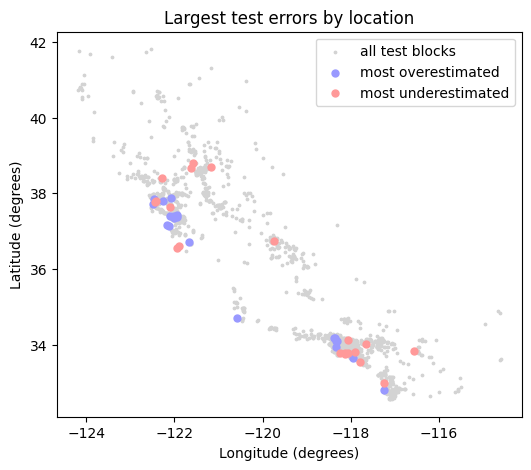

over, SF Area: 11 of 20
under, LA Area: 8 of 20


In [75]:
plt.figure(figsize=(6, 5))
plt.scatter(test["longitude"], test["latitude"], s=3, c="lightgrey", label="all test blocks")
plt.scatter(test.loc[top_over, "longitude"], test.loc[top_over, "latitude"], s=25, c="#9999ff", label="most overestimated")
plt.scatter(test.loc[top_under, "longitude"], test.loc[top_under, "latitude"], s=25, c="#ff9999", label="most underestimated")
plt.xlabel("Longitude (degrees)"); plt.ylabel("Latitude (degrees)")
plt.legend(); plt.title("Largest test errors by location")
plt.show()

def in_box(idx, lon_lo, lon_hi, lat_lo, lat_hi):
    t = test.loc[idx]
    return ((t["longitude"].between(lon_lo, lon_hi)) &
            (t["latitude"].between(lat_lo, lat_hi))).sum()

print("over, SF Area:", in_box(top_over, -122.6, -121.8, 37.0, 38.0), "of 20")
print("under, LA Area:", in_box(top_under, -118.5, -117.5, 33.5, 34.2), "of 20")


In [76]:
bay = test["longitude"].between(-122.6, -121.8) & test["latitude"].between(37.0, 38.0)
la = test["longitude"].between(-118.5, -117.5) & test["latitude"].between(33.5, 34.2)

print("Bay box: ", round(100 * bay.mean(), 1), "% of all test blocks")
print("LA box:  ", round(100 * la.mean(), 1), "% of all test blocks")


Bay box:  16.2 % of all test blocks
LA box:   33.4 % of all test blocks
